# Reasoning agent

The agent decides whether a query follows from a knowledge base.

- A hidden test file already contains first-order logic. The inference function reads those formulas and returns True or False. A result that the solver does not settle stays Unresolved. It is not stored as False.
- The public datasets are scored only when `RECHECK_RESULTS` is True. RuleTaker is English, translated into rules and tested by forward chaining. CounterBench is English, translated into a twin-network causal theory and tested by fast resolution. FOLIO is used as the supplied logic and tested with Z3.

Final True/False decisions come from these classical procedures, not from a generative model.


## 1. Configuration

Edit this cell before running the notebook.

- `INPUT_CSV`: the test file, placed in the same folder as this notebook.
- `RECHECK_RESULTS`: False runs only the logic inference on that file. True also scores the local public datasets and rewrites `submission.csv`.


In [4]:
from pathlib import Path
import os

print("Current working directory:", Path.cwd())
print("\nFiles in current directory:")

for path in Path.cwd().iterdir():
    print(path.name)

Current working directory: E:\Soundarya\AI_ASSIGNMENT_M24MA2004

Files in current directory:
.ipynb_checkpoints
anaconda_projects
datasets_local
datasets_unified
README.txt
reasoning_agent.ipynb
Report.pdf
submission.csv


In [5]:
from pathlib import Path

matches = list(Path.cwd().resolve().rglob("fol_engine.py"))

if matches:
    for path in matches:
        print("Found:", path)
else:
    print("fol_engine.py is missing from this directory tree.")

fol_engine.py is missing from this directory tree.


In [1]:
INPUT_CSV = "hidden_test.csv"
RECHECK_RESULTS = True

print("INPUT_CSV =", INPUT_CSV)
print("RECHECK_RESULTS =", RECHECK_RESULTS)


INPUT_CSV = hidden_test.csv
RECHECK_RESULTS = True


## 2. Setup


In [2]:
import re
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

def locate_project() -> Path:
    """Find the project that contains the reasoning modules."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "fol_engine.py").is_file():
            return folder
    raise FileNotFoundError(
        "fol_engine.py was not found in this folder or any parent folder."
    )

ROOT = locate_project()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from fol_engine import answer
from nl_to_fol_pipeline import horn_entails, translate_counterbench, translate_ruletaker
from resolution_engine import correctness_tests, resolve_query

DATA = ROOT / "datasets_unified"
LOCAL = ROOT / "datasets_local"
HERE = Path.cwd().resolve()
Z3_TIMEOUT_MS = 1000
RESOLUTION_LIMIT = 0.3

def normalize_logic(text: str) -> str:
    """Accept the ASCII spellings as well as the logical symbols."""
    text = str(text)
    text = text.replace("⊤", "True").replace("⊥", "False")
    text = re.sub(r"<->|<-->|<=>", "↔", text)
    text = re.sub(r"—>|-->|->|=>", "→", text)
    text = re.sub(r"\bforall\b", "∀", text, flags=re.IGNORECASE)
    text = re.sub(r"\bexists\b", "∃", text, flags=re.IGNORECASE)
    text = re.sub(r"\bxor\b", "⊕", text, flags=re.IGNORECASE)
    text = re.sub(r"\bnot\b", "¬", text, flags=re.IGNORECASE)
    text = re.sub(r"\band\b", "∧", text, flags=re.IGNORECASE)
    text = re.sub(r"\bor\b", "∨", text, flags=re.IGNORECASE)
    text = text.replace("~", "¬").replace("&", "∧").replace("|", "∨")
    return text

def predict_logic(context: str, statement: str, timeout_ms: int = Z3_TIMEOUT_MS):
    """Decide whether the statement follows from the context.

    Both arguments are logical formulas. The context has one formula per line.
    Returns the Answer object. prediction is True, False, or None.
    None means the solver did not settle the query. It is not a False answer.
    """
    facts = "\n".join(
        normalize_logic(line) for line in str(context).splitlines() if str(line).strip()
    )
    query = normalize_logic(statement)
    return answer(facts, query, timeout_ms=timeout_ms, align=False, unique_names=True)

def prediction_name(value):
    if value is True:
        return "True"
    if value is False:
        return "False"
    return "Unresolved"

def format_time(mean, deviation):
    if mean is None:
        return "n/a"
    if mean < 0.001:
        return f"{mean:.6f} ± {deviation:.6f}"
    return f"{mean:.4f} ± {deviation:.4f}"

def gold_is_true(value):
    """True only for an explicit True label. Uncertain and every other label count as False."""
    if pd.isna(value):
        return None
    text = str(value).strip().lower()
    if text in {"", "nan", "none"}:
        return None
    return text == "true"

def score_frame(frame, prediction_column="prediction", label_column="label"):
    gold = frame[label_column].map(gold_is_true)
    pred = frame[prediction_column]
    comparable = gold.notna()
    decided = comparable & pred.notna()
    correct = int((pred[decided] == gold[decided]).sum())
    total = int(comparable.sum())
    evaluated = int(decided.sum())
    unresolved = int((comparable & pred.isna()).sum())
    operational = 100.0 * correct / total if total else None
    evaluated_accuracy = 100.0 * correct / evaluated if evaluated else None
    return {
        "examples": total,
        "correct": correct,
        "evaluated": evaluated,
        "unresolved": unresolved,
        "operational": operational,
        "evaluated_accuracy": evaluated_accuracy,
    }

def confusion(frame, prediction_column="prediction", label_column="label"):
    gold = frame[label_column].map(gold_is_true)
    pred = frame[prediction_column]
    mask = gold.notna() & pred.notna()
    g = gold[mask]
    p = pred[mask]
    return {
        "TP": int(((p == True) & (g == True)).sum()),
        "FN": int(((p == False) & (g == True)).sum()),
        "FP": int(((p == True) & (g == False)).sum()),
        "TN": int(((p == False) & (g == False)).sum()),
    }

def show(title, metrics, seconds):
    print(title)
    print(f"  examples             {metrics['examples']}")
    print(f"  operational accuracy {metrics['operational']:.2f}%  ({metrics['correct']}/{metrics['examples']})")
    if metrics["evaluated"]:
        print(f"  evaluated accuracy   {metrics['evaluated_accuracy']:.2f}%  ({metrics['correct']}/{metrics['evaluated']})")
    print(f"  coverage             {100.0 * metrics['evaluated'] / metrics['examples']:.2f}%")
    print(f"  unresolved           {metrics['unresolved']}")
    print(f"  reasoning time       {format_time(seconds.mean(), seconds.std(ddof=1))} s/sample")

def print_split_table(title, frame, split_column=None):
    """Print the split accuracy table used in the report, plus reasoning time."""
    blocks = []
    if split_column is not None:
        for name, part in frame.groupby(split_column, sort=False):
            blocks.append((str(name), part))
    blocks.append(("All", frame))
    rows = []
    for name, part in blocks:
        metrics = score_frame(part)
        rows.append({
            "split": name,
            "examples": metrics["examples"],
            "correct": metrics["correct"],
            "accuracy_%": round(metrics["operational"], 2),
        })
    print(title)
    print(pd.DataFrame(rows).to_string(index=False))
    seconds = frame["seconds"]
    deviation = float(seconds.std(ddof=1)) if len(seconds) > 1 else 0.0
    print(f"reasoning time  {format_time(float(seconds.mean()), deviation)} s/sample")


def combined_line(dataset, method, frames):
    correct = 0
    examples = 0
    for frame in frames:
        metrics = score_frame(frame)
        correct += metrics["correct"]
        examples += metrics["examples"]
    accuracy = 100.0 * correct / examples if examples else None
    return {
        "dataset": dataset,
        "method": method,
        "examples": examples,
        "correct": correct,
        "accuracy_%": None if accuracy is None else round(accuracy, 2),
    }


print("project", ROOT)
print("notebook folder", HERE)


FileNotFoundError: fol_engine.py was not found in this folder or any parent folder.

## 3. Inference on logic

`predict_logic(context, statement)` is the function used for a file that is already logic. The context is one formula per line. The statement is one formula. Z3 tests whether the premises and the negation of the query can be true together. If they cannot, the query follows and the answer is True. If they can, the answer is False. If the solver stops without either answer, the prediction is Unresolved.


In [ ]:
demo_context = """
Young(Bob)
Kind(Bob)
∀x (Young(x) → Smart(x))
∀x (Smart(x) ∧ Kind(x) → Successful(x))
"""
demo = predict_logic(demo_context, "Successful(Bob)")
print("Successful(Bob) ->", prediction_name(demo.prediction), f"({demo.status}, {demo.seconds:.4f} s)")

ascii_context = """
Young(Bob)
Kind(Bob)
forall x (Young(x) -> Smart(x))
forall x (Smart(x) & Kind(x) -> Successful(x))
"""
ascii_demo = predict_logic(ascii_context, "Successful(Bob)")
print("ASCII spelling ->", prediction_name(ascii_demo.prediction), f"({ascii_demo.status})")

negative = predict_logic("Young(Bob)", "Kind(Bob)")
print("Kind(Bob) from Young(Bob) only ->", prediction_name(negative.prediction), f"({negative.status})")
checks = correctness_tests()
print("resolution checks", sum(item["passed"] for item in checks), "/", len(checks))


## 4. Hidden test file

The file needs the columns `id`, `context`, and `statement`. `label` is optional. A missing file does not stop the notebook. When the file is present, this cell prints the number of examples, the inference time, the accuracy if labels are present, and the TP / FN / FP / TN counts, then writes `submission_test.csv`.


In [3]:
test_path = Path(INPUT_CSV)
if not test_path.is_file():
    test_path = HERE / INPUT_CSV

if not test_path.is_file():
    print(f"No test file named {INPUT_CSV} in {HERE}.")
    print("Place the file next to the notebook, or change INPUT_CSV, then run this cell again.")
else:
    hidden = pd.read_csv(test_path)
    required = {"context", "statement"}
    missing = required - set(hidden.columns)
    if missing:
        raise ValueError(f"{test_path.name} is missing columns: {sorted(missing)}")
    if "id" not in hidden.columns:
        hidden.insert(0, "id", range(1, len(hidden) + 1))
        print("The file has no id column. Sample numbers were used.")

    records = []
    started = time.perf_counter()
    for row in hidden.itertuples(index=False):
        result = predict_logic(row.context, row.statement)
        records.append({
            "id": row.id,
            "prediction": result.prediction,
            "seconds": result.seconds,
            "status": result.status,
            "label": getattr(row, "label", None) if "label" in hidden.columns else None,
        })
    elapsed = time.perf_counter() - started
    hidden_result = pd.DataFrame(records)
    flags = hidden_result["prediction"].map(prediction_name)
    submission_test = pd.DataFrame({"id": hidden_result["id"], "flag": flags})
    submission_test_path = HERE / "submission_test.csv"
    submission_test.to_csv(submission_test_path, index=False)

    print(f"file                 {test_path}")
    print(f"examples             {len(hidden_result)}")
    print(f"inference time       {elapsed:.4f} s total")
    seconds = hidden_result["seconds"]
    if len(seconds) > 1:
        print(f"reasoning time       {format_time(seconds.mean(), seconds.std(ddof=1))} s/sample")
    print("statuses")
    print(hidden_result["status"].value_counts().to_string())
    if "label" in hidden.columns:
        metrics = score_frame(hidden_result)
        counts = confusion(hidden_result)
        print(f"operational accuracy {metrics['operational']:.2f}%  ({metrics['correct']}/{metrics['examples']})")
        if metrics["evaluated"]:
            print(f"evaluated accuracy   {metrics['evaluated_accuracy']:.2f}%  ({metrics['correct']}/{metrics['evaluated']})")
        print(f"unresolved           {metrics['unresolved']}")
        print("TP {TP}   FN {FN}   FP {FP}   TN {TN}".format(**counts))
        print("Uncertain and any label other than True are counted as False.")
        print("Unresolved predictions are left out of TP, FN, FP, and TN, and they count as incorrect in the operational accuracy.")
    else:
        print("The file has no label column, so accuracy is not computed.")
    print("wrote", submission_test_path, f"({len(submission_test)} rows)")
    print(submission_test.head(10).to_string(index=False))


NameError: name 'HERE' is not defined

## 5. Public datasets

The next cells run only when `RECHECK_RESULTS` is True. They read the local dataset files, score each experiment, and write `submission.csv`.

Last measured run, with Unresolved counted as incorrect:

| Dataset | Samples | Method | Operational accuracy | Reasoning time (s/sample) |
|---|---:|---|---:|---:|
| RuleTaker | 1625 | forward chaining | 98.46% (1600/1625) | 0.000012 ± 0.000003 |
| CounterBench | 1200 | twin network, fast resolution | 94.58% (1135/1200) | 0.0022 ± 0.0048 |
| FOLIO, Uncertain removed | 811 | Z3 on the supplied logic | 76.82% (623/811) | 0.0234 ± 0.0600 |
| FOLIO, Uncertain as False | 1204 | Z3 on the supplied logic | 82.48% (993/1204) | 0.0309 ± 0.0619 |

With `RECHECK_RESULTS` set to True, each dataset cell prints the split accuracy and the reasoning time, and the last cell prints the combined scores from the report.


### 5.1 RuleTaker

English facts and rules become Horn clauses. Forward chaining derives everything the rules produce and checks whether the query is among those facts.


In [5]:
SUMMARIES = []
PREDICTIONS = []

if not RECHECK_RESULTS:
    print("Skipped. Set RECHECK_RESULTS = True to score RuleTaker.")
else:
    if not LOCAL.is_dir():
        raise FileNotFoundError(f"Local datasets were not found at {LOCAL}")
    ruletaker = pd.concat([
        pd.read_csv(LOCAL / "ruletaker_train.csv").assign(split="train"),
        pd.read_csv(LOCAL / "ruletaker_test.csv").assign(split="test"),
        pd.read_csv(LOCAL / "ruletaker_ood_test.csv").assign(split="ood_test"),
    ], ignore_index=True)
    rows = []
    for sample_no, row in enumerate(ruletaker.itertuples(index=False), start=1):
        theory = translate_ruletaker(row.context, row.statement)
        if theory.status == "ok":
            prediction, status, seconds = horn_entails(theory.premises, theory.query)
        else:
            seconds = 0.0
            prediction = None
            status = theory.status
        rows.append({
            "split": row.split,
            "label": row.flag,
            "prediction": prediction,
            "seconds": seconds,
            "status": status,
        })
        PREDICTIONS.append({
            "dataset": "RuleTaker",
            "sample_no": sample_no,
            "prediction": prediction_name(prediction),
        })
    rt = pd.DataFrame(rows)
    rt_metrics = score_frame(rt)
    show("RuleTaker, forward chaining", rt_metrics, rt["seconds"])
    print_split_table("RuleTaker", rt, "split")
    SUMMARIES.append({
        "dataset": "RuleTaker",
        "method": "forward chaining",
        "samples": rt_metrics["examples"],
        "operational_accuracy": rt_metrics["operational"],
        "evaluated_accuracy": rt_metrics["evaluated_accuracy"],
        "coverage": 100.0 * rt_metrics["evaluated"] / rt_metrics["examples"],
        "reasoning_seconds": format_time(rt["seconds"].mean(), rt["seconds"].std(ddof=1)),
    })


RuleTaker, forward chaining
  examples             1625
  operational accuracy 98.46%  (1600/1625)
  evaluated accuracy   98.46%  (1600/1625)
  coverage             100.00%
  unresolved           0
  reasoning time       0.000012 ± 0.000003 s/sample
RuleTaker
   split  examples  correct  accuracy_%
   train      1000      983       98.30
    test       250      244       97.60
ood_test       375      373       99.47
     All      1625     1600       98.46
reasoning time  0.000012 ± 0.000003 s/sample


### 5.2 CounterBench

Each example becomes a factual world and a counterfactual world. An intervention removes the structural equation of the intervened event and sets that event to false in the counterfactual world. Fast resolution then tests the query. Fast resolution uses the same proof rules as plain resolution, plus a predicate index, unit subsumption, and unit simplification.


In [6]:
if not RECHECK_RESULTS:
    print("Skipped. Set RECHECK_RESULTS = True to score CounterBench.")
else:
    counterbench = pd.read_csv(DATA / "counterbench_unified.csv")
    rows = []
    for sample_no, row in enumerate(counterbench.itertuples(index=False), start=1):
        theory = translate_counterbench(row.facts, row.query)
        if theory.status == "ok":
            outcome = resolve_query(
                list(theory.premises),
                theory.query,
                RESOLUTION_LIMIT,
                True,
                unique_names=False,
            )
            prediction = outcome.prediction
            seconds = outcome.seconds
            status = outcome.status
        else:
            prediction = None
            seconds = 0.0
            status = theory.status
        rows.append({
            "label": row.label,
            "prediction": prediction,
            "seconds": seconds,
            "status": status,
        })
        PREDICTIONS.append({
            "dataset": "CounterBench",
            "sample_no": sample_no,
            "prediction": prediction_name(prediction),
        })
    cb = pd.DataFrame(rows)
    cb_metrics = score_frame(cb)
    show("CounterBench, fast resolution on the twin network", cb_metrics, cb["seconds"])
    print(cb["status"].value_counts().to_string())
    print_split_table("CounterBench", cb)
    SUMMARIES.append({
        "dataset": "CounterBench",
        "method": "fast resolution",
        "samples": cb_metrics["examples"],
        "operational_accuracy": cb_metrics["operational"],
        "evaluated_accuracy": cb_metrics["evaluated_accuracy"],
        "coverage": 100.0 * cb_metrics["evaluated"] / cb_metrics["examples"],
        "reasoning_seconds": format_time(cb["seconds"].mean(), cb["seconds"].std(ddof=1)),
    })


CounterBench, fast resolution on the twin network
  examples             1200
  operational accuracy 94.58%  (1135/1200)
  evaluated accuracy   94.58%  (1135/1200)
  coverage             100.00%
  unresolved           0
  reasoning time       0.0022 ± 0.0048 s/sample
status
not_entailed    630
entailed        570
CounterBench
split  examples  correct  accuracy_%
  All      1200     1135       94.58
reasoning time  0.0022 ± 0.0048 s/sample


### 5.3 FOLIO, supplied logic, Uncertain removed

The logic shipped with FOLIO is used as given. Z3 is the same solver as `predict_logic`, here with predicate alignment turned on because the FOLIO annotations sometimes spell the same predicate in more than one way. This block keeps only the original True and False labels.


In [7]:
if not RECHECK_RESULTS:
    print("Skipped. Set RECHECK_RESULTS = True to score FOLIO.")
else:
    folio = pd.read_csv(DATA / "folio_fol_unified.csv")
    rows = []
    for sample_no, row in enumerate(folio.itertuples(index=False), start=1):
        outcome = answer(row.facts, row.query, timeout_ms=Z3_TIMEOUT_MS, align=True, unique_names=True)
        rows.append({
            "label": row.label,
            "prediction": outcome.prediction,
            "seconds": outcome.seconds,
            "status": outcome.status,
        })
        PREDICTIONS.append({
            "dataset": "FOLIO FOL",
            "sample_no": sample_no,
            "prediction": prediction_name(outcome.prediction),
        })
    fol = pd.DataFrame(rows)
    fol_metrics = score_frame(fol)
    show("FOLIO FOL, Uncertain removed, Z3", fol_metrics, fol["seconds"])
    print(fol["status"].value_counts().to_string())
    split_rows = []
    for split_name, file_name in (("train", "folio_train.jsonl"), ("validation", "folio_validation.jsonl")):
        part = pd.read_json(LOCAL / file_name, lines=True)
        part = part[part["label"].astype(str).str.lower() != "uncertain"]
        split_rows.extend([split_name] * len(part))
    fol["split"] = split_rows
    print_split_table("FOLIO, Uncertain removed", fol, "split")
    SUMMARIES.append({
        "dataset": "FOLIO FOL",
        "method": "Z3",
        "samples": fol_metrics["examples"],
        "operational_accuracy": fol_metrics["operational"],
        "evaluated_accuracy": fol_metrics["evaluated_accuracy"],
        "coverage": 100.0 * fol_metrics["evaluated"] / fol_metrics["examples"],
        "reasoning_seconds": format_time(fol["seconds"].mean(), fol["seconds"].std(ddof=1)),
    })


FOLIO FOL, Uncertain removed, Z3
  examples             811
  operational accuracy 76.82%  (623/811)
  evaluated accuracy   77.01%  (623/809)
  coverage             99.75%
  unresolved           2
  reasoning time       0.0234 ± 0.0600 s/sample
status
not_entailed    484
entailed        325
unknown           2
FOLIO, Uncertain removed
     split  examples  correct  accuracy_%
     train       677      514       75.92
validation       134      109       81.34
       All       811      623       76.82
reasoning time  0.0234 ± 0.0600 s/sample


### 5.4 FOLIO, Uncertain counted as False

Every original row is kept. Entailment and True become True. Contradiction, False, and Uncertain become False. The formulas are still the supplied logic, and the solver is still Z3. The solver's own unknown result is not changed into False.


In [8]:
def folio_label(value):
    text = str(value).strip().lower()
    if text in {"entailment", "true"}:
        return True
    if text in {"contradiction", "false", "uncertain"}:
        return False
    raise ValueError(f"unrecognised FOLIO label: {value}")

if not RECHECK_RESULTS:
    print("Skipped. Set RECHECK_RESULTS = True to score FOLIO with Uncertain as False.")
else:
    parts = []
    for name in ("folio_train.jsonl", "folio_validation.jsonl"):
        part = pd.read_json(LOCAL / name, lines=True)
        part["source_split"] = name
        parts.append(part)
    source = pd.concat(parts, ignore_index=True)
    rows = []
    for sample_no, (_, row) in enumerate(source.iterrows(), start=1):
        outcome = answer(
            str(row["premises-FOL"]),
            str(row["conclusion-FOL"]),
            timeout_ms=Z3_TIMEOUT_MS,
            align=True,
            unique_names=True,
        )
        rows.append({
            "label": folio_label(row["label"]),
            "original_label": row["label"],
            "split": "train" if "train" in str(row["source_split"]) else "validation",
            "prediction": outcome.prediction,
            "seconds": outcome.seconds,
            "status": outcome.status,
        })
        PREDICTIONS.append({
            "dataset": "FOLIO FOL uncertain as False",
            "sample_no": sample_no,
            "prediction": prediction_name(outcome.prediction),
        })
    uncertain = pd.DataFrame(rows)
    unc_metrics = score_frame(uncertain)
    show("FOLIO FOL, Uncertain counted as False, Z3", unc_metrics, uncertain["seconds"])
    print("original labels")
    print(uncertain["original_label"].value_counts().to_string())
    print(uncertain["status"].value_counts().to_string())
    binary = uncertain[uncertain["original_label"].str.lower() != "uncertain"]
    binary_metrics = score_frame(binary)
    print(
        f"binary subset        {binary_metrics['operational']:.2f}%  "
        f"({binary_metrics['correct']}/{binary_metrics['examples']})"
    )
    print_split_table("FOLIO, Uncertain counted as False", uncertain, "split")
    print_split_table("FOLIO binary subset", binary, "split")
    SUMMARIES.append({
        "dataset": "FOLIO FOL uncertain as False",
        "method": "Z3",
        "samples": unc_metrics["examples"],
        "operational_accuracy": unc_metrics["operational"],
        "evaluated_accuracy": unc_metrics["evaluated_accuracy"],
        "coverage": 100.0 * unc_metrics["evaluated"] / unc_metrics["examples"],
        "reasoning_seconds": format_time(uncertain["seconds"].mean(), uncertain["seconds"].std(ddof=1)),
    })


FOLIO FOL, Uncertain counted as False, Z3
  examples             1204
  operational accuracy 82.48%  (993/1204)
  evaluated accuracy   82.68%  (993/1201)
  coverage             99.75%
  unresolved           3
  reasoning time       0.0309 ± 0.0619 s/sample
original labels
original_label
True         460
Uncertain    393
False        351
status
not_entailed    854
entailed        347
unknown           3
binary subset        76.82%  (623/811)
FOLIO, Uncertain counted as False
     split  examples  correct  accuracy_%
     train      1001      818       81.72
validation       203      175       86.21
       All      1204      993       82.48
reasoning time  0.0309 ± 0.0619 s/sample
FOLIO binary subset
     split  examples  correct  accuracy_%
     train       677      514       75.92
validation       134      109       81.34
       All       811      623       76.82
reasoning time  0.0309 ± 0.0617 s/sample


### 5.5 Comparison

`submission.csv` has one row per public example: the dataset name, the sample number inside that dataset, and the prediction. Unresolved is written as Unresolved.


                     dataset           method  samples  operational_accuracy  evaluated_accuracy   coverage   reasoning_seconds
                   RuleTaker forward chaining     1625             98.461538           98.461538 100.000000 0.000012 ± 0.000003
                CounterBench  fast resolution     1200             94.583333           94.583333 100.000000     0.0022 ± 0.0048
                   FOLIO FOL               Z3      811             76.818742           77.008653  99.753391     0.0234 ± 0.0600
FOLIO FOL uncertain as False               Z3     1204             82.475083           82.681099  99.750831     0.0309 ± 0.0619

Overall, Uncertain removed
     dataset           method  examples  correct  accuracy_%
   RuleTaker forward chaining      1625     1600       98.46
CounterBench  fast resolution      1200     1135       94.58
       FOLIO               Z3       811      623       76.82
   All three                       3636     3358       92.35
RuleTaker reasoning time   

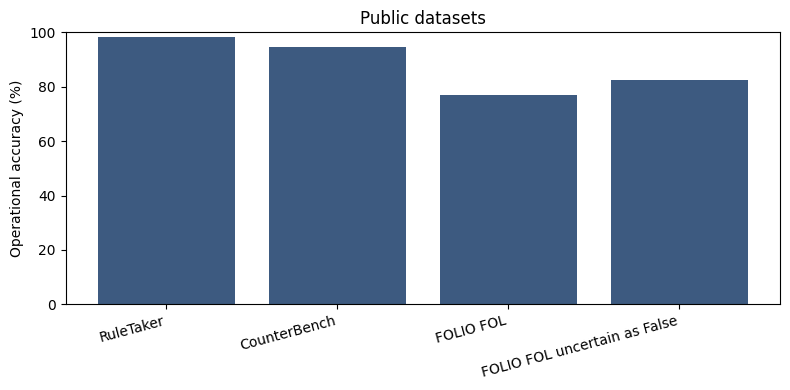

In [9]:
if not RECHECK_RESULTS:
    print("Skipped. Set RECHECK_RESULTS = True to rewrite submission.csv.")
else:
    summary = pd.DataFrame(SUMMARIES)
    print(summary.to_string(index=False))

    binary = uncertain[uncertain["original_label"].astype(str).str.lower() != "uncertain"]
    print()
    print("Overall, Uncertain removed")
    overall = pd.DataFrame([
        combined_line("RuleTaker", "forward chaining", [rt]),
        combined_line("CounterBench", "fast resolution", [cb]),
        combined_line("FOLIO", "Z3", [fol]),
        combined_line("All three", "", [rt, cb, fol]),
    ])
    print(overall.to_string(index=False))
    print(f"RuleTaker reasoning time          {format_time(rt['seconds'].mean(), rt['seconds'].std(ddof=1))} s/sample")
    print(f"CounterBench reasoning time       {format_time(cb['seconds'].mean(), cb['seconds'].std(ddof=1))} s/sample")
    print(f"FOLIO removed reasoning time      {format_time(fol['seconds'].mean(), fol['seconds'].std(ddof=1))} s/sample")
    print(f"FOLIO as False reasoning time     {format_time(uncertain['seconds'].mean(), uncertain['seconds'].std(ddof=1))} s/sample")

    compare_rows = []
    for split_name in ("train", "validation"):
        full = uncertain[uncertain["split"] == split_name]
        removed = full[full["original_label"].astype(str).str.lower() != "uncertain"]
        for label, part in (("removed", removed), ("counted as False", full)):
            metrics = score_frame(part)
            compare_rows.append({
                "data": f"FOLIO {split_name}",
                "uncertain": label,
                "examples": metrics["examples"],
                "correct": metrics["correct"],
                "accuracy_%": round(metrics["operational"], 2),
            })
    for label, part in (("removed", binary), ("counted as False", uncertain)):
        metrics = score_frame(part)
        compare_rows.append({
            "data": "FOLIO all",
            "uncertain": label,
            "examples": metrics["examples"],
            "correct": metrics["correct"],
            "accuracy_%": round(metrics["operational"], 2),
        })
    for label, frames in (
        ("removed", [rt, cb, fol]),
        ("counted as False", [rt, cb, uncertain]),
    ):
        line = combined_line("All three", "", frames)
        compare_rows.append({
            "data": "All three",
            "uncertain": label,
            "examples": line["examples"],
            "correct": line["correct"],
            "accuracy_%": line["accuracy_%"],
        })
    print()
    print("Uncertain removed or counted as False")
    print(pd.DataFrame(compare_rows).to_string(index=False))
    submission = pd.DataFrame(PREDICTIONS)
    submission_path = HERE / "submission.csv"
    submission.to_csv(submission_path, index=False)
    print("wrote", submission_path, f"({len(submission)} rows)")
    print(submission.groupby(["dataset", "prediction"]).size().unstack(fill_value=0).to_string())

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(summary["dataset"], summary["operational_accuracy"], color="#3d5a80")
    ax.set_ylim(0, 100)
    ax.set_ylabel("Operational accuracy (%)")
    ax.set_title("Public datasets")
    plt.xticks(rotation=15, ha="right")
    fig.tight_layout()
    plt.show()
